# 17. Primer candidato a modelo original: PT-bagging (histórico)

:::{admonition} Capítulo histórico: primer candidato a modelo original
:class: note
Este capítulo documenta **PT-bagging, el primer candidato a modelo original, que no superó a los benchmarks**, y sus
cuatro iteraciones de diseño. Se conserva como registro de los candidatos probados (guía §13; tabla de la sección 19.9).
Los pendientes que listaba la versión preliminar del 2026-10-21 quedaron superados o descartados:

- el árbol propio, la confirmación en la prueba y la corrida en el diseño del grupo ya no aplican, porque el modelo
  original final es **SECR (capítulo 19)** y la prueba de octubre a diciembre quedó bloqueada (capítulo 00, B1);
- las tres pruebas de hipótesis con Holm y δ de Cliff están en el **capítulo 20**;
- la declaración de uso de herramientas de IA está en el capítulo 14;
- `pytest tests/test_original_model.py` ya se corrió en el entorno del repositorio (sección 17.4).
:::

**Cómo se lee este capítulo.**
- Todas las tablas se leen de `results/modelo_original/`, que tiene resúmenes sin identificadores.
- El código que las produjo está en `disenio_temporal/` (ver su `LEEME.md`).
- Esas corridas usaron scikit-learn 1.2.2, imbalanced-learn 0.11.0 y xgboost 2.1.4. El resto del repositorio usa
  1.3.0, 0.12.4 y 2.1.3.
- **Observado** es lo que se lee en una tabla; **interpretación** es la lectura que hacemos de ella.

**Veredicto adelantado.**
- R1 (novedad de aplicación): sí, de forma provisional (capítulo 16).
- R2 (implementación propia): quedó en riesgo (árbol de scikit-learn sin modificar); por eso se pasó a SECR (capítulo 19).
- R3 (superioridad): **no**. PT-bagging no supera a los modelos del curso.

In [1]:
import sys, inspect, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import balanced_accuracy_score
from osha_e3 import config as C, plots as P
from osha_e3.original_model import PTBagging
P.setup()
R = C.RESULTS / 'modelo_original'
NOMBRES = {'pt_bagging': 'PT-bagging', 'pt_bagging_sin_umbral': 'PT-bagging sin umbral (ablación A)',
           'multirandbal': 'MultiRandBal', 'hierarchical': 'Metaclasificación jerárquica',
           'hafl_xgboost': 'HAFL-XGBoost', 'hafl_xgboost_gamma0': 'HAFL-XGBoost con γ = 0 (ablación)',
           'xgboost__class_weight__bayes': 'XGBoost + class_weight + bayesiano (referencia)',
           'xgboost__class_weight__random': 'XGBoost + class_weight + aleatorio'}
OPT = {'grid': 'Rejilla', 'random': 'Aleatoria', 'bayes': 'Bayesiano', 'genetic': 'Genético'}
COLS = {'muertes_acertadas': 'Muertes acertadas', 'muertes': 'Muertes', 'casos_marcados': 'Casos marcados como Fall.',
        'recall_2_4': 'Recall 2–4', 'auc_macro': 'AUC macro', 'balanced_accuracy': 'BA', 'kappa': 'Kappa',
        'log_loss': 'Log-loss'}

## 17.1 Motivación

El problema tiene un desbalance extremo: Fallecimiento es alrededor del 0,03 % de los casos (69 muertes en
269.516 casos de desarrollo), y las otras tres clases rondan un tercio cada una. Los capítulos 6 a 9 tratan el
desbalance antes o durante el entrenamiento, con SMOTE, ADASYN o `class_weight`. Esas técnicas cambian los datos o
la pérdida, y con eso cambian también las probabilidades que estima el modelo.

PT-bagging (Collell, Prelec y Patil, 2018) toma el camino contrario:
- entrena con la **distribución natural** de las clases, para estimar bien `P(y = k | x)`;
- corrige el desbalance **solo al decidir**, con una regla cerrada que maximiza la balanced accuracy, que es la
  métrica del proyecto.

No es una red neuronal, y la regla de decisión no está en scikit-learn ni en imbalanced-learn.

## 17.2 Formulación

Sea $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{n}$ con $y_i \in \{1, \dots, K\}$ y proporciones de clase
$\lambda_k = \frac{1}{n}\sum_i \mathbb{1}[y_i = k]$. El método tiene tres pasos.

**1. Bolsas.** Para $b = 1, \dots, B$ se toma una muestra bootstrap $\mathcal{D}_b$ de tamaño $n$, con reemplazo y
sin estratificar, y se entrena un árbol sin podar $T_b$ con criterio de entropía. Cada hoja guarda la proporción
de cada clase entre los casos que caen en ella.

**2. Promedio.**

$$
\hat P(y = k \mid x) = \frac{1}{B}\sum_{b=1}^{B} \hat P_{T_b}(y = k \mid x)
$$ (pt-promedio)

**3. Decisión con umbral igual al prior.**

$$
\hat h(x) = \arg\max_{k} \; \frac{\hat P(y = k \mid x)}{\lambda_k}
$$ (pt-regla)

La implementación devuelve como `predict_proba` el puntaje normalizado
$s_k(x) = \frac{\hat P(k \mid x)/\lambda_k}{\sum_j \hat P(j \mid x)/\lambda_j}$. Así, `predict` es igual a
`argmax(predict_proba)`, como en el resto del pipeline. Las probabilidades sin reponderar están en
`predict_proba_raw`.

**Teorema 1 (Collell et al., 2018).** Sea $h^*(x) = \arg\max_k P(y = k \mid x)/\lambda_k$, con las probabilidades
verdaderas. Entonces $h^*$ maximiza la *macro-accuracy*

$$
\mathrm{MA}(h) = \frac{1}{K}\sum_{k=1}^{K} P\big(h(X) = k \mid Y = k\big),
$$ (pt-ma)

que es la balanced accuracy de la población.

*Demostración.* Por la definición de probabilidad condicional,
$P(h(X) = k \mid Y = k) = \mathbb{E}\big[\mathbb{1}[h(X) = k]\,\mathbb{1}[Y = k]\big]/\lambda_k$. Condicionando
en $X$:

$$
\mathrm{MA}(h) = \frac{1}{K}\,\mathbb{E}_X\Big[\sum_{k} \mathbb{1}[h(X) = k]\,\frac{P(Y = k \mid X)}{\lambda_k}\Big]
            = \frac{1}{K}\,\mathbb{E}_X\Big[\frac{P(Y = h(X) \mid X)}{\lambda_{h(X)}}\Big].
$$ (pt-demo)

Para cada $x$ fijo, el integrando depende solo de la etiqueta que se le asigna a $x$. Por eso se maximiza punto
a punto eligiendo la clase con mayor $P(Y = k \mid x)/\lambda_k$, y maximizar en cada punto maximiza la
esperanza. $\blacksquare$

**Supuesto clave.** El teorema usa las probabilidades **verdaderas**. Con $\hat P$ estimado, la regla
{eq}`pt-regla` es óptima solo si $\hat P$ está bien calibrado. Con 16 a 37 muertes de entrenamiento por pliegue no
lo está, y eso explica los resultados de 17.5 y 17.6.

## 17.3 Pseudocódigo y complejidad

```
Entrada: X (n × d, one-hot disperso), y; B árboles; semilla s
λ_k ← proporción de la clase k en y
rng ← generador con semilla s
para b = 1..B:
    I_b ← n índices al azar con reemplazo (rng)
    T_b ← árbol(criterio = entropía, sin podar, semilla = rng) entrenado con (X[I_b], y[I_b])
predecir(x):
    P ← (1/B) Σ_b P_{T_b}(· | x)                 # ecuación (pt-promedio)
    devolver argmax_k P_k / λ_k                    # ecuación (pt-regla)
```

Los índices y las semillas de las B bolsas se sortean **antes** de entrenar. Por eso entrenar en hilos
(`n_jobs`) da exactamente el mismo modelo; la prueba (ii) de 17.4 lo verifica.

**Complejidad** (con $n$ casos, $d$ columnas one-hot, $B$ árboles, $K$ clases y $h$ la profundidad del árbol):
- **Entrenamiento:** $O(B\, d\, n \log n)$ si los árboles están balanceados. Un árbol sin podar puede degenerar
  hasta $O(B\, d\, n^2)$. La regla de decisión no cuesta nada al entrenar.
- **Predicción:** $O(B\,(h + K))$ por caso.
- **Memoria:** $O(B \cdot \text{hojas} \cdot K)$.

La tabla siguiente muestra los tiempos medidos. En la Fase A, con el árbol del paper, el tiempo crece algo más que
linealmente con $n$. En la Fase B, los árboles podados que eligen los optimizadores se reajustan mucho más rápido.

In [2]:
t = pd.read_csv(R / 'tiempos_pt_bagging.csv')
t['optimizador'] = t['optimizador'].replace(OPT)
t.rename(columns={'fase': 'Fase', 'optimizador': 'Optimizador', 'pliegue': 'Pliegue', 'filas_entrenamiento': 'Filas',
                  'columnas_onehot': 'Columnas one-hot', 'n_estimators': 'Árboles', 'min_samples_leaf': 'Mín. por hoja',
                  'segundos_ajuste': 'Ajuste (s)', 'segundos_total': 'Total (s)',
                  'segundos_por_evaluacion': 's por evaluación', 'segundos_prediccion': 'Predicción (s)'})

,Fase,Optimizador,Pliegue,Filas,Columnas one-hot,Árboles,Mín. por hoja,Ajuste (s),Total (s),s por evaluación,Predicción (s)
0,A (paper: 100 árboles sin podar),ninguno,1,56063,1172,100,1,467.1,469.3,NaN,NaN
1,A (paper: 100 árboles sin podar),ninguno,2,95908,1241,100,1,1043.8,1046.6,NaN,NaN
2,A (paper: 100 árboles sin podar),ninguno,3,138669,1283,100,1,1819.3,1822.0,NaN,NaN
3,B (reajuste con el mejor de la búsqueda),Bayesiano,1,56063,472,117,1,63.4,842.1,64.7,0.52
4,B (reajuste con el mejor de la búsqueda),Bayesiano,2,95908,1241,101,21,347.8,1998.8,137.3,0.59
5,B (reajuste con el mejor de la búsqueda),Bayesiano,3,138669,252,175,24,1198.9,3667.5,205.3,0.97
6,B (reajuste con el mejor de la búsqueda),Genético,1,56063,778,147,4,45.5,852.5,67.1,0.59
7,B (reajuste con el mejor de la búsqueda),Genético,2,95908,487,210,17,717.4,2324.2,133.6,0.77
8,B (reajuste con el mejor de la búsqueda),Genético,3,138669,1283,209,15,481.8,3012.1,210.5,0.82
9,B (reajuste con el mejor de la búsqueda),Rejilla,1,56063,1172,100,1,30.3,760.6,60.7,0.53


**Tabla 17.1. Tiempos de PT-bagging (pared, 1 hilo por proceso).**
- En la Fase A, el ajuste pasa de 467 s con 56.063 filas a 1.819 s con 138.669: con 2,5 veces más filas tarda
  3,9 veces más.
- Predecir unos 20.000 casos de validación tarda entre 0,5 y 1,4 s.
- «s por evaluación» es el tiempo medio de una configuración en la búsqueda interna (muestra del 25 %).

## 17.4 Código y pruebas unitarias

El estimador está en `src/osha_e3/original_model.py`. La clase base `_TreeEnsemble` entrena los árboles y promedia
sus probabilidades; `PTBagging` añade el bootstrap y la regla de decisión:

In [3]:
from osha_e3 import original_model as OM
print(inspect.getsource(OM._TreeEnsemble))
print(inspect.getsource(OM.PTBagging))

class _TreeEnsemble(BaseEstimator, ClassifierMixin):
    """Base común: entrena ``n_estimators`` árboles, cada uno sobre las filas que da ``_sample``,
    y promedia sus probabilidades."""

    def _tree(self, seed):
        return DecisionTreeClassifier(criterion=self.criterion, max_depth=self.max_depth,
                                      min_samples_leaf=self.min_samples_leaf, ccp_alpha=self.ccp_alpha,
                                      max_features=self.max_features, random_state=seed)

    def _fit_trees(self, X, y, samples, seeds):
        # Las muestras y semillas ya están fijadas, así que entrenar en hilos (n_jobs) no cambia el resultado.
        from joblib import Parallel, delayed

        def fit_one(idx, seed):
            return self._tree(int(seed)).fit(_rows(X, idx), y[idx])
        self.estimators_ = Parallel(n_jobs=getattr(self, 'n_jobs', 1), prefer='threads')(
            delayed(fit_one)(idx, seed) for idx, seed in zip(samples, seeds))
        return self

    d

Las pruebas están en `tests/test_original_model.py`. Las cuatro que pide la sección 5.4 de la guía son:

| Prueba | Qué verifica |
|---|---|
| (i) `test_pt_i_aprende_solucion_conocida` | Clasifica perfecto cuando la clase es función determinista de una variable. Con una clase rara, `argmax(P/λ)` acierta al menos tanto de esa clase como `argmax(P)`. |
| (ii) `test_pt_ii_reproducible_con_semilla` | Misma semilla, mismas probabilidades; otra semilla, otras bolsas; `n_jobs = 2` da lo mismo que `n_jobs = 1`. |
| (iii) `test_pt_iii_entradas_invalidas` | `NotFittedError` si se predice sin ajustar; `ValueError` con NaN o con otro número de columnas. |
| (iv) `test_pt_iv_compatible_con_clone` | `sklearn.base.clone` copia los hiperparámetros sin el estado ajustado y reproduce el ajuste. |

El archivo tiene además pruebas de la regla `P/λ`, de las cuatro iteraciones de diseño, de que no haya fuga
(la predicción no depende de las etiquetas del conjunto que se predice) y de las derivadas de HAFL comparadas con
diferencias finitas.

**Resultado:** 29 pruebas pasan y 0 fallan. Se ejecutaron el 2026-10-21 en el entorno de `disenio_temporal/` con un
ejecutor mínimo equivalente, porque pytest no está instalado en ese entorno. **Actualización (2026-10-23):**
`pytest tests/test_original_model.py` en el entorno del repositorio (scikit-learn 1.3.0, imbalanced-learn 0.12.4 y
xgboost 2.1.3) da **29 de 29 aprobadas**. Antes fallaba la prueba (iii): desde scikit-learn 1.3 el árbol acepta NaN y
`PTBagging.fit` ya no los rechazaba; ahora valida la entrada con `check_array(..., force_all_finite=True)`. La suite
completa (`pytest tests/`) da 44 de 44.

**Ilustración del Teorema 1 con datos sintéticos.** La celda siguiente usa datos con una clase rara (~1 %) y compara
la balanced accuracy con y sin umbral, en una partición aparte de prueba:

In [4]:
rng = np.random.default_rng(C.SEED)
n = 6000
y = rng.choice([1, 2, 3, 4], size=n, p=[0.01, 0.33, 0.33, 0.33])
Xs = rng.integers(0, 6, size=(n, 6))
Xs[:, 0] = np.where((y == 1) & (rng.random(n) < 0.7), 0, Xs[:, 0])   # la clase rara prefiere la categoría 0
Xs[:, 1] = (Xs[:, 1] + y) % 6                                          # señal débil para las demás clases
X = np.hstack([np.eye(6)[Xs[:, j]] for j in range(6)])
tr, te = np.arange(n) < 4000, np.arange(n) >= 4000
demo = []
for thr, nombre in [('prior', 'argmax P/λ (PT-bagging)'), (None, 'argmax P (sin umbral)')]:
    m = PTBagging(n_estimators=50, min_samples_leaf=20, threshold=thr, random_state=C.SEED).fit(X[tr], y[tr])
    pred = m.predict(X[te])
    demo.append({'Regla': nombre, 'BA en prueba sintética': balanced_accuracy_score(y[te], pred),
                 'Recall de la clase rara': np.mean(pred[y[te] == 1] == 1), 'Casos rara en prueba': int((y[te] == 1).sum())})
pd.DataFrame(demo).set_index('Regla').round(3)

,BA en prueba sintética,Recall de la clase rara,Casos rara en prueba
Regla,,,
argmax P/λ (PT-bagging),0.330,0.524,21
argmax P (sin umbral),0.255,0.000,21


**Tabla 17.2. Ilustración sintética.** Aquí las hojas tienen al menos 20 casos, así que $\hat P$ de la clase rara no
es cero, y el umbral cambia las decisiones como predice el teorema. En los datos de OSHA, la Fase A usa árboles sin
podar: casi todas las hojas tienen $\hat P(\text{Fall.}) = 0$ y el umbral no tiene sobre qué actuar (17.5).

## 17.5 Fase A: cribado con los hiperparámetros del paper

**Diseño.**
- Diseño temporal de 3 pliegues externos (capítulo 12.6): 61.649 casos de validación y 12 muertes en total.
- Hiperparámetros del paper: 100 árboles sin podar, sin optimizador.
- Tres candidatos de la literatura (capítulo 16): PT-bagging, MultiRandBal y metaclasificación jerárquica.
- Referencias: las 8 combinaciones de XGBoost y Random Forest con `class_weight`.
- La regla de decisión se escribió **antes** de ver los números (`regla_decision.md`): un candidato pasa si acierta
  más muertes con las mismas falsas alarmas que la referencia, o las mismas muertes marcando menos casos.

In [5]:
cr = pd.read_csv(R / 'cribado.csv')
sel = ['pt_bagging', 'pt_bagging_sin_umbral', 'multirandbal', 'hierarchical',
       'xgboost__class_weight__bayes', 'xgboost__class_weight__random']
fa = cr[(cr.pliegue == 'todos') & cr.modelo.isin(sel)].set_index('modelo').loc[sel]
fa.index = fa.index.map(NOMBRES)
fa[list(COLS)].rename(columns=COLS).round(3)

,Muertes acertadas,Muertes,Casos marcados como Fall.,Recall 2–4,AUC macro,BA,Kappa,Log-loss
modelo,,,,,,,,
PT-bagging,1,12,296,0.487,0.644,0.386,0.231,1.635
PT-bagging sin umbral (ablación A),0,12,1,0.485,0.644,0.364,0.229,1.619
MultiRandBal,0,12,21,0.482,0.631,0.361,0.222,1.252
Metaclasificación jerárquica,0,12,0,0.495,0.684,0.371,0.243,1.214
XGBoost + class_weight + bayesiano (referencia),8,12,5337,0.466,0.704,0.516,0.228,1.107
XGBoost + class_weight + aleatorio,0,12,57,0.527,0.745,0.395,0.287,0.964


**Tabla 17.3. Fase A, los 3 pliegues juntos.**

Observado:
- Ningún candidato cumple la regla (`decision_fase_a.md`).
- PT-bagging acierta 1 de 12 muertes y marca 296 casos. La referencia acierta 8 de 12 y marca 5.337.
- Los tres candidatos tienen AUC macro y log-loss peores que la referencia.
- Por la regla de respaldo pasa a la Fase B el que más muertes acierta con menos casos marcados: PT-bagging.

Interpretación:
- Los árboles sin podar dan probabilidades casi 0/1. Según `proba_raw` de las predicciones guardadas, el 99,2 %,
  el 99,7 % y el 99,6 % de los casos de validación reciben $\hat P(\text{Fall.}) = 0$ exacto en los pliegues 1, 2
  y 3. Cero dividido por $\lambda$ sigue siendo cero.
- Solo 1 de las 12 muertes tiene $\hat P > 0$, y es la única que se acierta.
- La metaclasificación jerárquica nunca marca Fallecimiento: su Naive Bayes de segundo nivel aprende el prior real.

## 17.6 Fase B: validación anidada y ablaciones

**Diseño.**
- Mismo bucle anidado que la corrida del capítulo 12.6: búsqueda en el 25 % del entrenamiento, 3 pliegues internos
  agrupados por establecimiento y reajuste al 100 %.
- 4 optimizadores × 3 pliegues, sin balanceo adicional: el método ya rebalancea al decidir, y añadir SMOTE o pesos
  lo haría dos veces.
- **12 evaluaciones por optimizador**, menos que las 20 de la corrida base. Fue un recorte declarado por la
  proyección de tiempo (`proyeccion_fase_b.md`). La proyección sobrestimó el tiempo unas 3,5 veces: con 20
  evaluaciones habría cabido. Antes de comparar con la referencia hay que igualar el presupuesto (pendiente).
- El punto del paper (100 árboles sin podar) está dentro de la rejilla.

In [6]:
fb = pd.read_csv(R / 'fase_b_resumen.csv')
por_pliegue = fb[fb.pliegue != 'todos'].groupby('optimizador').balanced_accuracy.mean()
tb = fb[fb.pliegue == 'todos'].set_index('optimizador').loc[list(OPT)]
tb['BA media por pliegue'] = por_pliegue
ref = cr[cr.modelo == 'xgboost__class_weight__bayes']
fila_ref = ref[ref.pliegue == 'todos'].iloc[0].copy()
fila_ref['BA media por pliegue'] = ref[ref.pliegue != 'todos'].balanced_accuracy.mean()
tb.loc['Referencia: XGBoost + cw + bayesiano'] = fila_ref
tb.index = [OPT.get(i, i) for i in tb.index]
cols = list(COLS) + ['BA media por pliegue']
tb[cols].astype(float).rename(columns=COLS).round(3)

,Muertes acertadas,Muertes,Casos marcados como Fall.,Recall 2–4,AUC macro,BA,Kappa,Log-loss,BA media por pliegue
Rejilla,5.0,12.0,14284.0,0.415,0.660,0.416,0.214,1.148,0.453
Aleatoria,10.0,12.0,22518.0,0.360,0.707,0.479,0.189,1.197,0.499
Bayesiano,9.0,12.0,18143.0,0.391,0.715,0.480,0.203,1.178,0.511
Genético,12.0,12.0,29384.0,0.307,0.690,0.480,0.161,1.230,0.480
Referencia: XGBoost + cw + bayesiano,8.0,12.0,5337.0,0.466,0.704,0.516,0.228,1.107,0.505


**Tabla 17.4. Fase B, los 3 pliegues juntos, y BA media por pliegue.**

Observado:
- Los optimizadores eligen árboles **podados** (tabla 17.5).
- Aciertan de 5 a 12 muertes, pero marcan de 14.284 a 29.384 casos, entre el 23 % y el 48 % de todos.
- El recall 2–4 y el kappa quedan por debajo de la referencia.
- La BA media por pliegue del bayesiano (0,511) es mayor que la de la referencia (0,505). Con los pliegues juntos es
  menor (0,480 frente a 0,516).

Interpretación:
- La diferencia en la BA media por pliegue viene de la única muerte del pliegue 1. Ahí acertar o fallar un solo
  caso mueve el recall de Fallecimiento entre 0 y 1, y la BA del pliegue en 0,25. **No se interpreta como
  superioridad.**

In [7]:
hp = pd.read_csv(R / 'fase_b_hiperparametros.csv')
hp['optimizador'] = hp['optimizador'].replace(OPT)
hp.drop(columns=['max_features', 'min_frequency', 'threshold']).rename(columns={'optimizador': 'Optimizador', 'pliegue': 'Pliegue'})

,Optimizador,Pliegue,n_estimators,max_depth,min_samples_leaf,ccp_alpha
0,Rejilla,1,100,10.0,1,0.000000
1,Rejilla,2,200,NaN,50,0.000000
2,Rejilla,3,200,NaN,10,0.000000
3,Aleatoria,1,138,12.0,9,0.000005
4,Aleatoria,2,295,47.0,37,0.000002
5,Aleatoria,3,256,30.0,14,0.000003
6,Bayesiano,1,117,15.0,1,0.000009
7,Bayesiano,2,101,50.0,21,0.000154
8,Bayesiano,3,175,58.0,24,0.000063
9,Genético,1,147,11.0,4,0.000081


**Tabla 17.5. Hiperparámetros elegidos en cada pliegue.**
- En el pliegue 1, la rejilla y el bayesiano eligen `min_samples_leaf` = 1. Las demás celdas eligen hojas de 4 a 50
  casos.
- Con hojas más grandes, $\hat P(\text{Fall.})$ deja de ser cero en muchos casos. Dividido por un prior de cerca de
  1/3.700, gana en demasiados: esa es la causa de los miles de casos marcados en la tabla 17.4.

**Ablaciones.**
- **A, sin umbral:** `argmax P` con los árboles de la Fase A. Acierta 0 de 12 muertes y marca 1 caso (tabla 17.3).
  El umbral es lo único que hace marcar Fallecimiento.
- **D, el umbral sin el bagging:** la misma regla `P/λ`, aplicada sin reajustar a las predicciones guardadas de
  Random Forest y XGBoost sin balanceo.

In [8]:
ab = pd.read_csv(R / 'ablacion_d_umbral_prior.csv')
ab['regla'] = ab['regla'].replace({'argmax_P': 'argmax P', 'P_entre_prior': 'argmax P/λ'})
ab.set_index(['modelo', 'regla'])[list(COLS)].rename(columns=COLS).round(3)

Muertes acertadas  Muertes  \
modelo                       regla                                    
random_forest__none__grid    argmax P                    0       12   
                             argmax P/λ                 10       12   
random_forest__none__random  argmax P                    0       12   
                             argmax P/λ                 11       12   
random_forest__none__bayes   argmax P                    0       12   
                             argmax P/λ                 10       12   
random_forest__none__genetic argmax P                    0       12   
                             argmax P/λ                 12       12   
xgboost__none__grid          argmax P                    0       12   
                             argmax P/λ                  7       12   
xgboost__none__random        argmax P                    0       12   
                             argmax P/λ                  5       12   
xgboost__none__bayes         argmax P                    0       12   
                             argmax P/λ                 11       12   
xgboost__none__genetic       argmax P                    0       12   
                             argmax P/λ                  6       12   

                                         Casos marcados como Fall.  \
modelo                       regla                                   
random_forest__none__grid    argmax P                            0   
                             argmax P/λ                      17878   
random_forest__none__random  argmax P                            0   
                             argmax P/λ                      15318   
random_forest__none__bayes   argmax P                            0   
                             argmax P/λ                      16662   
random_forest__none__genetic argmax P                            0   
                             argmax P/λ                      12435   
xgboost__none__grid          argmax P                            0   
                             argmax P/λ                       8393   
xgboost__none__random        argmax P                            0   
                             argmax P/λ                      10271   
xgboost__none__bayes         argmax P                            0   
                             argmax P/λ                      30830   
xgboost__none__genetic       argmax P                            0   
                             argmax P/λ                       9902   

                                         Recall 2–4  AUC macro     BA  Kappa  \
modelo                       regla                                             
random_forest__none__grid    argmax P         0.501      0.743  0.376  0.254   
                             argmax P/λ       0.394      0.728  0.504  0.206   
random_forest__none__random  argmax P         0.518      0.758  0.388  0.276   
                             argmax P/λ       0.418      0.744  0.543  0.223   
random_forest__none__bayes   argmax P         0.516      0.754  0.387  0.274   
                             argmax P/λ       0.407      0.733  0.513  0.215   
random_forest__none__genetic argmax P         0.519      0.763  0.390  0.279   
                             argmax P/λ       0.439      0.746  0.579  0.234   
xgboost__none__grid          argmax P         0.518      0.721  0.389  0.278   
                             argmax P/λ       0.464      0.709  0.494  0.245   
xgboost__none__random        argmax P         0.522      0.703  0.391  0.283   
                             argmax P/λ       0.458      0.699  0.448  0.247   
xgboost__none__bayes         argmax P         0.521      0.720  0.390  0.281   
                             argmax P/λ       0.284      0.678  0.442  0.140   
xgboost__none__genetic       argmax P         0.525      0.717  0.394  0.287   
                             argmax P/λ       0.460      0.712  0.470  0.248   

                                         Log-loss  
modelo  

**Tabla 17.6. Ablación D.**

Observado: Random Forest + genético + `P/λ` acierta 12 de 12 muertes marcando 12.435 casos. PT-bagging con el
genético acierta las mismas 12 marcando 29.384. Además, Random Forest tiene mejor recall 2–4 y mejor AUC.

Interpretación: **el ingrediente que funciona es el umbral, no el bagging de árboles sin podar.** Un Random
Forest común da probabilidades más útiles para ese umbral. La ablación estaba prevista en la especificación y no
se usa para elegir un modelo nuevo.

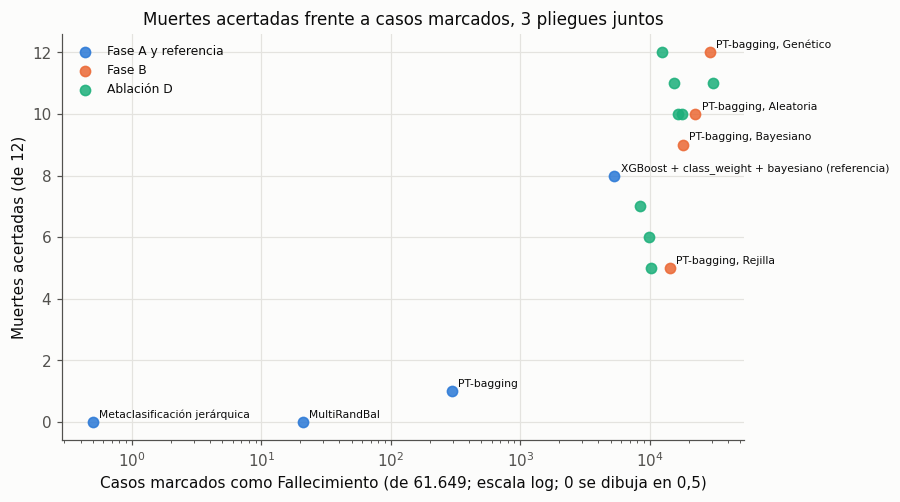

In [9]:
pts = [(NOMBRES[m], fa.loc[NOMBRES[m], 'casos_marcados'], fa.loc[NOMBRES[m], 'muertes_acertadas'], 'Fase A y referencia')
       for m in ['pt_bagging', 'multirandbal', 'hierarchical', 'xgboost__class_weight__bayes']]
pts += [(f'PT-bagging, {OPT[o]}', r.casos_marcados, r.muertes_acertadas, 'Fase B')
        for o, r in fb[fb.pliegue == 'todos'].set_index('optimizador').iterrows()]
pts += [(m.replace('__none__', ' sin balanceo, ').replace('_', ' '), r.casos_marcados, r.muertes_acertadas, 'Ablación D')
        for m, r in ab[ab.regla == 'argmax P/λ'].set_index('modelo').iterrows()]
d = pd.DataFrame(pts, columns=['modelo', 'marcados', 'acertadas', 'grupo'])
fig, ax = plt.subplots(figsize=(8, 4.8))
for (g, sub), col in zip(d.groupby('grupo', sort=False), P.SERIES):
    ax.scatter(sub.marcados.clip(lower=0.5), sub.acertadas, label=g, color=col, s=45, alpha=.85)
for _, r in d[d.grupo != 'Ablación D'].iterrows():
    ax.annotate(r.modelo, (max(r.marcados, 0.5), r.acertadas), fontsize=7, xytext=(4, 3), textcoords='offset points')
ax.set_xscale('log')
ax.set_xlabel('Casos marcados como Fallecimiento (de 61.649; escala log; 0 se dibuja en 0,5)')
ax.set_ylabel('Muertes acertadas (de 12)')
ax.set_title('Muertes acertadas frente a casos marcados, 3 pliegues juntos')
ax.legend(frameon=False, fontsize=8)
P.save(fig, 'e3_original_muertes_vs_marcados')
plt.show()

**Figura 17.1.** Cada punto es un modelo, con los 3 pliegues de validación juntos.

Observado: ninguna variante de PT-bagging queda por encima y a la izquierda de la referencia, es decir, con más
muertes acertadas marcando menos casos. Las variantes de la Fase B y de la ablación D aciertan más muertes solo
porque marcan muchos más casos.

Interpretación: con 12 muertes de validación no hay un punto intermedio estable. El modelo o no marca casi nada
(árboles sin podar) o marca decenas de miles de casos (árboles podados).

## 17.7 Iteraciones del diseño: Rondas 2 a 4

Como PT-bagging no mejoró, se probaron cuatro variantes más, siguiendo la Figura 2 de la guía (iterar el diseño).
Cada una tuvo su regla escrita antes de calcular (`regla_r2.md`, `regla_r3.md` y `regla_r4.md`). Ninguna se
presenta como modelo original.

| Ronda | Iteración | Fuente | Resultado |
|---|---|---|---|
| 1 | MultiRandBal; metaclasificación jerárquica | Rodríguez et al. (*KBS*, 2020); Bhattacharya et al. (*BMC MIDM*, 2018) | Fase A: 0 de 12 muertes; no pasan |
| 2 | HAFL-XGBoost (pérdida focal con γ adaptativo como objetivo propio de XGBoost) | Jiang et al. (*Neural Comput. & Applic.*, 2023) | Con los mismos casos marcados que la referencia: 8 de 12 frente a 8 de 12; no pasa |
| 3 | Subproblema de las clases 2–4 (exploratorio) | — | Los cuatro candidatos quedan por debajo de la mejor base |
| 4 | Frank–Hall ordinal con XGBoost (exploratorio y posterior) | Frank y Hall (ECML, 2001) | BA 2–4: −0,0025 (IC 95 %: −0,0055 a +0,0004); no pasa |

In [10]:
r2 = pd.read_csv(R / 'cribado_r2.csv')
r2 = r2[r2.pliegue == 'todos'].copy()
r2['modelo'] = r2['modelo'].map(NOMBRES)
r2['decision'] = r2['decision'].replace({'argmax': 'argmax propio', 'k_igual_ref': 'mismos casos marcados que la referencia'})
r2.set_index(['modelo', 'decision'])[['muertes_acertadas', 'casos_marcados', 'aucpr_fall', 'recall_2_4', 'auc_macro',
                                      'balanced_accuracy']].rename(columns=COLS | {'aucpr_fall': 'AUC-PR Fall.'}).round(4)

Muertes acertadas  \
modelo                                          decision                                                     
XGBoost + class_weight + bayesiano (referencia) argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   
HAFL-XGBoost                                    argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   

                                                                                         Casos marcados como Fall.  \
modelo                                          decision                                                             
XGBoost + class_weight + bayesiano (referencia) argmax propio                                                 5337   
                                                mismos casos marcados que la referencia                       5337   
HAFL-XGBoost                                    argmax propio                                                 4321   
                                                mismos casos marcados que la referencia                       5337   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                                 4242   
                                                mismos casos marcados que la referencia                       5337   

                                                                                         AUC-PR Fall.  \
modelo                                          decision                                                
XGBoost + class_weight + bayesiano (referencia) argmax propio                                  0.0018   
                                                mismos casos marcados que la referencia        0.0018   
HAFL-XGBoost                                    argmax propio                                  0.0019   
                                                mismos casos marcados que la referencia        0.0019   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                  0.0020   
                                                mismos casos marcados que la referencia        0.0020   

                                                                                         Recall 2–4  \
modelo                                          decision                                              
XGBoost + class_weight + bayesiano (referencia) argmax propio                                0.4657   
                                                mismos casos marcados que la referencia      0.4648   
HAFL-XGBoost                                    argmax propio                                0.4741   
                                                mismos casos marcados que la referencia      0.4659   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                0.4752   
                                                mismos casos marcados que la referencia      0.4664   

                                                                                         AUC macro  \
modelo                                          decision                                             
XGBoost + class_weight + bayesiano (referencia) argmax propio                               0.7036   
                                                mismos casos marcados que la referencia     0.7036   
HAFL-XGBoost                                    argmax propio                               0.7030   
                                                mismos casos marcados que la referencia

**Tabla 17.7. Ronda 2: HAFL-XGBoost.**
- Las derivadas de la pérdida focal (gradiente y hessiano diagonal) se programaron a mano. Se comprobaron con
  diferencias finitas para γ entre 0 y 5.
- Con los mismos casos marcados que la referencia, acierta las mismas 8 muertes. No pasa la regla.
- Con su propio `argmax`, marca menos casos. La ablación con γ = 0 da lo mismo, así que esa diferencia viene del
  objetivo propio (hessiano exacto), no de la pérdida focal.

In [11]:
c24 = pd.read_csv(R / 'comparaciones_2_4.csv')
c24['modelo'] = c24['modelo'].map(NOMBRES)
c24.set_index('modelo')[['delta_ba_2_4', 'delta_low_holm', 'delta_high_holm', 'p_mcnemar_holm', 'mejora']].rename(
    columns={'delta_ba_2_4': 'Δ BA 2–4 frente a la mejor base', 'delta_low_holm': 'IC inferior (Holm)',
             'delta_high_holm': 'IC superior (Holm)', 'p_mcnemar_holm': 'p McNemar (Holm)', 'mejora': '¿Mejora?'}).round(4)

,Δ BA 2–4 frente a la mejor base,IC inferior (Holm),IC superior (Holm),p McNemar (Holm),¿Mejora?
modelo,,,,,
PT-bagging,-0.0382,-0.0502,-0.0284,0.0,False
MultiRandBal,-0.0458,-0.0573,-0.0361,0.0,False
Metaclasificación jerárquica,-0.0327,-0.0422,-0.0241,0.0,False
HAFL-XGBoost,-0.0250,-0.0335,-0.0180,0.0,False
HAFL-XGBoost con γ = 0 (ablación),-0.0245,NaN,NaN,NaN,NaN


**Tabla 17.8. Ronda 3: clases 2–4.**
- Diseño: 61.637 casos y 15.897 establecimientos, solo con predicciones guardadas. Se compara con la mejor de las
  108 combinaciones base (XGBoost + `class_weight` + aleatorio, BA 2–4 = 0,527).
- Los intervalos son de un bootstrap pareado por establecimiento (2.000 réplicas), con nivel ajustado por Holm.
- Los cuatro candidatos quedan por debajo, con intervalos que excluyen el cero.
- Esta ronda encontró estructura ordinal en los errores: el 71,6 % de los errores de la base son entre clases
  adyacentes. Eso motivó la Ronda 4.

In [12]:
r4 = pd.read_csv(R / 'tabla_r4.csv').set_index('modelo')
r4.index = r4.index.map({'base': 'Mejor base (XGBoost + cw + aleatorio)', 'frank_hall': 'Frank–Hall ordinal',
                         'control': 'Control: el mismo pipeline multiclase reajustado'})
r4[['ba_2_4', 'ba_2_4_low', 'ba_2_4_high', 'kappa_cuadratico_2_4', 'frac_no_adyacente_2_4',
    '4clases_muertes_acertadas', '4clases_casos_marcados']].rename(columns={
    'ba_2_4': 'BA 2–4', 'ba_2_4_low': 'IC inf.', 'ba_2_4_high': 'IC sup.', 'kappa_cuadratico_2_4': 'Kappa cuadrático',
    'frac_no_adyacente_2_4': 'Errores no adyacentes', '4clases_muertes_acertadas': 'Muertes acertadas',
    '4clases_casos_marcados': 'Casos marcados'}).round(4)

,BA 2–4,IC inf.,IC sup.,Kappa cuadrático,Errores no adyacentes,Muertes acertadas,Casos marcados
modelo,,,,,,,
Mejor base (XGBoost + cw + aleatorio),0.5274,0.5188,0.5365,0.2962,0.3664,0,57
Frank–Hall ordinal,0.5249,0.5162,0.5336,0.2916,0.3500,0,37
Control: el mismo pipeline multiclase reajustado,0.5274,0.5188,0.5365,0.2962,0.3664,0,57


**Tabla 17.9. Ronda 4: Frank–Hall ordinal.**
- La fila «Control» reajusta el mismo pipeline multiclase de la base y reproduce sus predicciones guardadas
  (diferencia máxima 0): solo cambia la descomposición ordinal.
- Usa el orden de gravedad de OSHA (Otro < Traslado < Días de ausencia < Fallecimiento) con 3 XGBoost binarios.
- Reduce un poco los errores no adyacentes, pero predice aún más la clase del medio.
- Δ BA 2–4 = −0,0025, con IC pareado de −0,0055 a +0,0004. No pasa (`decision_r4.md`).
- Limitación: los hiperparámetros se tomaron de la base multiclase y no se optimizaron para la versión ordinal.

**Cinco candidatos probados; ninguno mejoró.** Elegir el mejor de varios intentos sobrestima su ventaja (efecto de
selección). Aquí no hay ventaja que corregir.

## 17.8 Por qué no se encuentra mejora: techo de información, fuga y efecto del empleador

**Techo de las 8 variables** (`sensibilidad_variables.md`). Es exploratorio: una sola partición y sin intervalos.
- Con las 8 variables del diseño, un *gradient boosting* llega a una BA 2–4 de 0,533, el mismo techo (~0,53) que
  toda la corrida base.
- Añadir naturaleza, parte del cuerpo, evento y fuente la sube a ~0,60. Pero esas variables salen de las
  narrativas y se excluyen por posible fuga.

**Fuga directa.** Proporción de casos de cada clase con el campo presente o mayor que cero:

In [13]:
J = R / 'justificacion'
display(pd.read_csv(J / 'fuga_directa.csv', index_col=0).rename(columns={'dafw>0': 'días de ausencia > 0',
        'djtr>0': 'días de traslado > 0', 'date_of_death': 'fecha de muerte presente'}).round(3))
display(pd.read_csv(J / 'fuga_narrativas.csv', index_col=0).round(4))
display(pd.read_csv(J / 'informacion_mutua.csv', index_col=0).round(3))

,días de ausencia > 0,días de traslado > 0,fecha de muerte presente
Fallecimiento,0.145,0.000,1.0
Días de ausencia,0.994,0.293,0.0
Traslado/restricción,0.004,0.995,0.0
Otro,0.002,0.003,0.0


,muerte,dias_de_ausencia,restriccion_o_traslado,regreso_al_trabajo,cualquiera
Fallecimiento,0.5362,0.0000,0.0000,0.0000,0.5362
Días de ausencia,0.0006,0.0037,0.0027,0.0017,0.0082
Traslado/restricción,0.0005,0.0010,0.0043,0.0015,0.0069
Otro,0.0005,0.0015,0.0016,0.0017,0.0050


,informacion_mutua_nats
nature_title_pred,0.132
source_title_pred,0.124
event_title_pred,0.113
naics_code,0.087
naics_3,0.069
soc_code,0.064
part_title_pred,0.056
type_of_incident,0.035
time_started_work,0.024
state,0.023


**Tablas 17.10 a 17.12. Fuga directa, menciones en las narrativas e información mutua con el desenlace (en nats).**
Todo se calculó solo con el desarrollo.

Observado:
- `dafw_num_away > 0` en el 99,4 % de la clase 2, `djtr_num_tr > 0` en el 99,5 % de la clase 3 y `date_of_death`
  en el 100 % de las muertes. Estos campos definen la etiqueta.
- Las narrativas nombran la muerte en el 54 % de los fallecimientos. En las clases 2–4, menos del 1 % menciona
  ausencia, restricción o regreso al trabajo (búsqueda aproximada de palabras clave).
- Las variables `*_pred` son las que más información comparten con el desenlace (0,11 a 0,13 nats, frente a 0,07
  de la industria a 3 dígitos).

Lo que dice la documentación de OSHA:
- Las `*_pred` las asigna OSHA con el autocodificador SOII de BLS, **a partir de las narrativas** (ITA Case Detail
  Data Dictionary).
- Los casos de un año se cargan entre el 2 de enero y el 2 de marzo del año siguiente (ITA Data Users Guide). En el
  desarrollo, la mediana de `created_timestamp` es 283 días después del incidente.

Interpretación: las narrativas y las `*_pred` se escriben cuando el desenlace ya se conoce. Por eso no están
disponibles «a tiempo» para predecirlo.

In [14]:
display(pd.read_csv(J / 'empleador_resumen.csv').rename(columns={'establecimientos': 'Establecimientos (≥ 20 casos 2–3)',
        'casos': 'Casos', 'var_z': 'var(z) observada', 'frac_abs_z_mayor_3': 'Fracción con |z| > 3'}).round(3))
pd.read_csv(J / 'empleador_agregado.csv').set_index('cuantil').round(3)

,Establecimientos (≥ 20 casos 2–3),Casos,var(z) observada,Fracción con |z| > 3
0,1416,72094,12.927,0.41


,z,prop_traslado,casos_por_establecimiento
cuantil,,,
0.00,-21.550,0.000,20.00
0.05,-5.312,0.000,20.00
0.10,-4.268,0.028,21.00
0.25,-2.235,0.161,24.00
0.50,0.373,0.470,32.00
0.75,2.683,0.720,49.00
0.90,4.573,0.872,87.00
0.95,5.621,0.933,131.75
1.00,13.093,1.000,2013.00


**Tablas 17.13 y 17.14. Efecto del empleador** (casos de las clases 2 y 3).

Cómo se mide:
- Para cada establecimiento se calcula un *z* que compara su proporción de traslado o restricción con la esperada
  según industria, naturaleza y parte del cuerpo.
- Sin efecto del empleador, var(z) ≈ 1. Al permutar dentro de cada estrato da 0,98.

Observado:
- var(z) = 12,9.
- El 41 % de los establecimientos tiene |z| > 3; sin efecto del empleador se esperaría un 0,3 %.
- Los cuantiles muestran establecimientos con 0 % y con 100 % de traslado.

Interpretación:
- Que un caso termine en días de ausencia o en trabajo restringido depende en buena parte de la política de
  trabajo liviano de cada empleador.
- La validación agrupa por establecimiento, así que el modelo nunca conoce la política del empleador de un caso
  nuevo.
- Esto pone un techo a cualquier método, original o del curso, con estas 8 variables.

## 17.9 Veredicto (histórico)

> **Superado.** Este veredicto es el del primer candidato. El veredicto del modelo original final (SECR) está en los
> capítulos 19 y 20 y en las conclusiones (R1 sí, R2 sí, R3 no).

| Requisito | Veredicto | Evidencia |
|---|---|---|
| R1, novedad | **Sí, provisional** | Capítulo 16: no se halló PT-bagging aplicado a la gravedad de lesiones laborales. Faltan una tercera base formal y la cadena de la búsqueda 2 de WoS. |
| R2, implementación propia | **En riesgo** | La regla de decisión, el bootstrap, el promedio y las pruebas son propios. El árbol interno es `DecisionTreeClassifier` sin modificar, que el Cuadro 1 de la guía no acepta. Plan: programar el árbol con numpy. |
| R3, superioridad | **No** | Fase A: 1 de 12 muertes frente a 8 de 12. Fase B: más muertes solo marcando de 14.000 a 29.000 casos. BA con los pliegues juntos: 0,480 frente a 0,516. Rondas 2–4: ninguna iteración pasa su regla. |

**Sobre la BA media por pliegue.** El bayesiano tiene 0,511 frente a 0,505 de la referencia. Se reporta, pero no
se reclama como superioridad: la diferencia la produce la única muerte del pliegue 1, y con los pliegues juntos el
orden se invierte.

Según la guía, con R1 y R2 en «sí» y R3 en «no», la nota máxima de esta componente es 4,0.

## 17.10 Limitaciones

1. **Pocas muertes.** Hay 12 muertes de validación en el diseño temporal y de 16 a 37 de entrenamiento por pliegue.
   El recall de Fallecimiento casi no se puede medir: el intervalo de Wilson para 8 de 12 va de 0,39 a 0,86.
2. **Diseño distinto al de los capítulos 6 a 13.** Las cifras son del diseño temporal de 3 pliegues (12.6). Falta
   correr el modelo en el diseño del grupo. El puente entre los dos diseños es la prueba oct–dic, que todavía no se
   usa.
3. **Presupuesto desigual.** La Fase B usó 12 evaluaciones por optimizador; la corrida base usó 20. Hay que
   igualarlo antes de la comparación final.
4. **Desviaciones del paper.** CART con entropía en lugar de J48 (C4.5), con divisiones binarias sobre el one-hot.
   En la Fase B se buscan hiperparámetros que el paper deja fijos, porque el curso exige 4 optimizadores.
5. **Árbol de scikit-learn** (riesgo de R2, ver 17.9; resuelto con SECR, capítulo 19).
6. **Rondas 3 y 4 exploratorias.** Se decidieron después de ver resultados; el efecto de selección se declara.
7. **Entorno distinto** al del resto del repositorio (versiones de scikit-learn, imbalanced-learn y xgboost; ver
   `disenio_temporal/LEEME.md`).
8. Las tres pruebas de hipótesis formales se hicieron para el modelo final (capítulo 20). La confirmación en la
   prueba se descartó: la prueba quedó bloqueada (capítulo 00, B1).